# PneumoLens | 01 Dataset Audit

### Phase 2 - Reproducible data quality and split-integrity audit

**Project:** Pediatric chest X-ray NORMAL vs PNEUMONIA classification  
**Source:** ZhangLab / Kermany pediatric chest X-ray collection; the attached Kaggle copy is the source of truth  
**Environment:** Kaggle Notebook (or local Python with a dataset folder / ZIP)  
**Status:** Audit workflow - not an approved clinical or patient-level validation study

> **Research/educational use only.** Folder labels are dataset annotations, not confirmed diagnoses. Filename-based `BACTERIA` and `VIRUS` labels must not be described as microbiologically verified. No patient identity is confirmed from filenames alone.

## tl;dr
This notebook produces a **traceable manifest**, quantifies dataset and label integrity, checks full image decode and byte-level duplication, flags image-similarity candidates, and explains whether the data are ready for EDA or training. It **never edits source images** and **never silently repartitions the original test set**. In the absence of trusted patient identifiers, patient-independent validation is **not established**.

**Run top to bottom.** Outputs are written to `OUTPUT_DIR`; do not commit images or personal identifiers to GitHub.

## 1. Context, assumptions, and setup

- **Unit of observation:** an image file, not automatically a unique patient.
- **Primary labels:** NORMAL / PNEUMONIA from the closest class folder under `chest_xray`.
- **Source split:** original `train`, `val`, or `test` folder name; this is not proof of patient independence.
- **Subtype:** optional BACTERIAL / VIRAL *filename tokens*, not pathogen-confirmed labels.
- **Filename group token:** may be a patient, study, series, or arbitrary token. Its meaning is **unverified** until source metadata confirms it.
- **Validation split:** **not generated by default**. An optional verified ID CSV can enable a grouped candidate split after hard checks pass.

Set `DATASET_SOURCE` only if auto-discovery is ambiguous. For your existing Kaggle hierarchy, the directory containing `srabondcosta/pneumonia/ZhangLabData/...` can be used; unrelated OCT images are inventoried but excluded from CXR analysis.

In [4]:
from __future__ import annotations

import os, re, json, sys, hashlib, platform, warnings, zipfile
from pathlib import Path, PurePosixPath
from contextlib import contextmanager
from collections import defaultdict
from datetime import datetime, timezone
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
from IPython.display import display

# ------------------------- CONFIGURATION -------------------------
INPUT_ROOT = Path(os.environ.get("PNEUMOLENS_INPUT_ROOT", "/kaggle/input"))
DATASET_SOURCE = os.environ.get("PNEUMOLENS_DATASET_SOURCE", "").strip() or None
OUTPUT_DIR = Path(os.environ.get(
    "PNEUMOLENS_OUTPUT_DIR",
    "/kaggle/working/pneumolens_phase2_audit_v2" if Path("/kaggle/working").exists()
    else "./pneumolens_phase2_audit_v2",
))

FULL_DECODE_CHECK = True       # A full image decode is more rigorous than a header-only check.
COMPUTE_SHA256 = True         # Byte-identical duplicates (not visually re-encoded duplicates).
COMPUTE_DHASH = True          # 64-bit dHash, for review candidates only.
NEAR_DUPLICATE_MAX_HAMMING = 4
MAX_NEAR_DUPLICATE_OUTPUT_ROWS = 1000
MAX_CROSS_SPLIT_DHASH_COMPARISONS = 6_000_000
SAVE_ALL_IMAGE_INVENTORY = True
SEED = 42

# Optional: CSV with EXACT columns 'relative_path' and 'verified_patient_id'.
# Only provide this when the patient identity mapping is independently verified.
VERIFIED_PATIENT_CSV = os.environ.get("PNEUMOLENS_VERIFIED_PATIENT_CSV", "").strip() or None
CREATE_VAL_IF_PATIENT_VERIFIED = False
VAL_FRACTION_OF_ORIGINAL_TRAIN = 0.12

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
CXR_FOLDERS = {"chestxray", "chestxrayimages", "cxr"}
ALLOWED_SPLITS = {"train", "val", "test"}
ALLOWED_CLASSES = {"NORMAL", "PNEUMONIA"}

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
np.random.seed(SEED)
pd.set_option("display.max_columns", 35)
pd.set_option("display.max_colwidth", 90)
print("PneumoLens | Phase 2 | Audit V2")
print("Python:", sys.version.split()[0], "| pandas:", pd.__version__, "| Pillow:", Image.__version__)
print("Input root:", INPUT_ROOT, "| outputs:", OUTPUT_DIR)

PneumoLens | Phase 2 | Audit V2
Python: 3.13.18 | pandas: 2.3.3 | Pillow: 13.0.0
Input root: /kaggle/input | outputs: /kaggle/working/pneumolens_phase2_audit_v2


## 2. Source discovery and file inventory

Inventory the attached source (an extracted folder or ZIP **without extracting it**). Paths in the manifest remain relative to that selected source, allowing traceability. If there is more than one plausible source, stop and set `DATASET_SOURCE` explicitly.

In [5]:
def resolve_source() -> Path:
    if DATASET_SOURCE:
        candidate = Path(DATASET_SOURCE)
    else:
        if not INPUT_ROOT.exists():
            raise FileNotFoundError(
                f"No input root {INPUT_ROOT}. Attach the dataset in Kaggle, "
                "or set PNEUMOLENS_DATASET_SOURCE to a local directory / ZIP."
            )
        children = sorted([p for p in INPUT_ROOT.iterdir() if not p.name.startswith(".")])
        if len(children) == 1:
            candidate = children[0]
        else:
            keywords = ("pneumonia", "chest", "xray", "x-ray", "zhanglab", "kermany")
            likely = [p for p in children if any(key in p.name.lower() for key in keywords)]
            if len(likely) != 1:
                raise RuntimeError(
                    "Multiple possible input sources. Set DATASET_SOURCE in the "
                    "configuration cell. Candidates: " + ", ".join(map(str, children))
                )
            candidate = likely[0]
    if not candidate.exists():
        raise FileNotFoundError(f"Selected data source not found: {candidate}")
    if candidate.is_file():
        if candidate.suffix.lower() != ".zip":
            raise ValueError(f"Expected directory or .zip; got {candidate}")
        return candidate
    if not candidate.is_dir():
        raise ValueError(f"Not a directory or ZIP: {candidate}")

    # If the selected directory contains only a single nested ZIP, use it directly.
    # Directories with image files should always be scanned as directories.
    nested_zips = sorted(candidate.rglob("*.zip"))
    if len(nested_zips) == 1:
        first_image = next(
            (p for p in candidate.rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS),
            None,
        )
        if first_image is None:
            return nested_zips[0]
    return candidate

selected_source = resolve_source()
source_type = "zip" if selected_source.is_file() else "directory"
print("Selected source:", selected_source)
print("Source type:", source_type)

Selected source: /kaggle/input/datasets
Source type: directory


In [6]:
def parts_of(path_text):
    return [part for part in PurePosixPath(str(path_text).replace("\\", "/")).parts if part not in ("", ".", "/")]

def normalized(part):
    return re.sub(r"[^a-z0-9]", "", part.lower())

def is_cxr_component(part):
    token = normalized(part)
    return token in CXR_FOLDERS or token.startswith("chestxray")

def get_split(path_text):
    aliases = {"train": "train", "training": "train", "val": "val",
               "valid": "val", "validation": "val", "test": "test", "testing": "test"}
    splits = [aliases[p.lower()] for p in parts_of(path_text)[:-1] if p.lower() in aliases]
    return splits[-1] if splits else "UNKNOWN"

def get_label_and_source(path_text):
    parts = parts_of(path_text)
    parent = parts[:-1]
    positions = [idx for idx, value in enumerate(parent) if is_cxr_component(value)]
    if positions:
        scoped_parent = parent[positions[-1]+1:]
    else:
        split_positions = [i for i, value in enumerate(parent) if value.lower() in
                           {"train", "training", "test", "testing", "val", "valid", "validation"}]
        scoped_parent = parent[split_positions[-1]+1:] if split_positions else []
    folders = [p.upper() for p in scoped_parent if p.upper() in ALLOWED_CLASSES]
    folder_label = folders[-1] if folders else "UNKNOWN"

    stem = PurePosixPath(parts[-1] if parts else "").stem.upper()
    if re.match(r"^NORMAL(?:[-_]|$)", stem):
        filename_label = "NORMAL"
    elif re.match(r"^(?:BACTERIA|BACTERIAL|VIRUS|VIRAL|PNEUMONIA)(?:[-_]|$)", stem):
        filename_label = "PNEUMONIA"
    else:
        filename_label = "UNKNOWN"
    disagreement = (folder_label != "UNKNOWN" and filename_label != "UNKNOWN"
                    and folder_label != filename_label)
    label = folder_label if folder_label != "UNKNOWN" else filename_label
    return label, folder_label, filename_label, disagreement

def get_subtype(path_text):
    stem = PurePosixPath(str(path_text).replace("\\", "/")).stem.lower()
    bac = bool(re.search(r"(?:^|[_-])(?:bacteria|bacterial)(?:$|[_-])", stem))
    vir = bool(re.search(r"(?:^|[_-])(?:virus|viral)(?:$|[_-])", stem))
    if bac and vir: return "AMBIGUOUS"
    if bac: return "BACTERIAL"
    if vir: return "VIRAL"
    return "UNKNOWN"

def numeric_group_candidate(path_text):
    stem = PurePosixPath(str(path_text).replace("\\", "/")).stem
    # This token is NOT a verified patient ID. Preserve leading zeroes.
    match = re.match(r"^(?:NORMAL|PNEUMONIA|BACTERIA|BACTERIAL|VIRUS|VIRAL)[_-](\d+)[_-]\d+$", stem, re.I)
    return match.group(1) if match else None

def get_modality_hint(path_text):
    parts = parts_of(path_text)
    par = parts[:-1]
    if any(is_cxr_component(value) for value in par):
        return "CHEST_XRAY_EXPLICIT"
    exclusions = {"oct", "oct2017", "cnv", "dme", "drusen", "retina", "retinal"}
    if any(normalized(value) in exclusions for value in par):
        return "NON_CXR_OCT_OR_RETINA"
    label, _, _, _ = get_label_and_source(path_text)
    if label in ALLOWED_CLASSES and get_split(path_text) != "UNKNOWN":
        # We do not silently treat other file types as medically validated CXRs.
        return "CHEST_XRAY_FALLBACK_REVIEW"
    return "UNCERTAIN"

def record_from_path(relative_path, byte_size, storage_type):
    rel = str(relative_path).replace("\\", "/")
    label, folder_label, filename_label, conflict = get_label_and_source(rel)
    return {
        "relative_path": rel,
        "filename": PurePosixPath(rel).name,
        "extension": PurePosixPath(rel).suffix.lower(),
        "file_size_bytes": int(byte_size),
        "storage_type": storage_type,
        "modality_hint": get_modality_hint(rel),
        "label": label,
        "folder_label": folder_label,
        "filename_label": filename_label,
        "folder_filename_label_conflict": bool(conflict),
        "original_split": get_split(rel),
        "subtype_filename_token": get_subtype(rel),
        "numeric_group_candidate_UNVERIFIED": numeric_group_candidate(rel),
    }

# Real filename-format tests for the original dataset copy.
assert get_label_and_source("ZhangLabData/CellData/chest_xray/train/NORMAL/NORMAL-1003233-0001.jpeg")[0] == "NORMAL"
assert get_label_and_source("srabondcosta/pneumonia/ZhangLabData/CellData/chest_xray/train/NORMAL/NORMAL-1003233-0001.jpeg")[0] == "NORMAL"
assert get_label_and_source("chest_xray/test/PNEUMONIA/VIRUS-490019-0001.jpeg")[0] == "PNEUMONIA"
assert get_modality_hint("OCT2017/train/CNV/CNV-100.jpg") == "NON_CXR_OCT_OR_RETINA"
assert numeric_group_candidate("VIRUS-00042-0003.jpeg") == "00042"
assert get_subtype("BACTERIA-5150733-0002.jpeg") == "BACTERIAL"
print("Parser checks passed.")

Parser checks passed.


In [7]:
inventory_rows = []
zip_handle = None
if source_type == "zip":
    zip_handle = zipfile.ZipFile(selected_source, mode="r")
    image_members = sorted(
        (item for item in zip_handle.infolist()
         if not item.is_dir()
         and PurePosixPath(item.filename).suffix.lower() in IMAGE_EXTENSIONS
         and "__MACOSX" not in PurePosixPath(item.filename).parts),
        key=lambda x: x.filename,
    )
    for item in tqdm(image_members, desc="Indexing ZIP images"):
        inventory_rows.append(record_from_path(item.filename, item.file_size, "zip"))
else:
    image_paths = sorted(p for p in selected_source.rglob("*")
                         if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS)
    for image_path in tqdm(image_paths, desc="Inventorying image files"):
        try:
            size = image_path.stat().st_size
        except OSError:
            size = -1
        inventory_rows.append(record_from_path(
            image_path.relative_to(selected_source).as_posix(), size, "directory"
        ))

inventory = pd.DataFrame(inventory_rows)
if inventory.empty:
    raise RuntimeError("No image files found. Review DATASET_SOURCE and supported extensions.")
if inventory["relative_path"].duplicated().any():
    raise RuntimeError("Duplicate archive paths / relative paths in the source. Review source before proceeding.")

# Only evidence-backed CXR candidates go to the primary manifest.
modality_mask = inventory["modality_hint"].isin(
    ["CHEST_XRAY_EXPLICIT", "CHEST_XRAY_FALLBACK_REVIEW"]
)
cxr = inventory.loc[modality_mask].copy().reset_index(drop=True)
if cxr.empty:
    raise RuntimeError("No chest X-ray candidates found; check selected source before training.")
cxr.insert(0, "image_id", [f"cxr_{i+1:06d}" for i in range(len(cxr))])
print(f"All image files: {len(inventory):,}")
print(f"Chest X-ray candidates: {len(cxr):,}")
print(f"Other / uncertain images: {len(inventory)-len(cxr):,}")
display(inventory["modality_hint"].value_counts().rename("count").to_frame())
display(cxr[["relative_path", "original_split", "label", "subtype_filename_token"]].head(8))

Inventorying image files:   0%|          | 0/115165 [00:00<?, ?it/s]

All image files: 115,165
Chest X-ray candidates: 5,856
Other / uncertain images: 109,309


,count
modality_hint,
NON_CXR_OCT_OR_RETINA,109309
CHEST_XRAY_EXPLICIT,5856


,relative_path,original_split,label,subtype_filename_token
0,srabondcosta/pneumonia/ZhangLabData/CellData/chest_xray/test/NORMAL/NORMAL-1049278-000...,test,NORMAL,UNKNOWN
1,srabondcosta/pneumonia/ZhangLabData/CellData/chest_xray/test/NORMAL/NORMAL-1110860-000...,test,NORMAL,UNKNOWN
2,srabondcosta/pneumonia/ZhangLabData/CellData/chest_xray/test/NORMAL/NORMAL-11419-0001....,test,NORMAL,UNKNOWN
3,srabondcosta/pneumonia/ZhangLabData/CellData/chest_xray/test/NORMAL/NORMAL-115218-0001...,test,NORMAL,UNKNOWN
4,srabondcosta/pneumonia/ZhangLabData/CellData/chest_xray/test/NORMAL/NORMAL-1160949-000...,test,NORMAL,UNKNOWN
5,srabondcosta/pneumonia/ZhangLabData/CellData/chest_xray/test/NORMAL/NORMAL-1212407-000...,test,NORMAL,UNKNOWN
6,srabondcosta/pneumonia/ZhangLabData/CellData/chest_xray/test/NORMAL/NORMAL-1228182-000...,test,NORMAL,UNKNOWN
7,srabondcosta/pneumonia/ZhangLabData/CellData/chest_xray/test/NORMAL/NORMAL-1283091-000...,test,NORMAL,UNKNOWN


## 3. Count and label audit

Use the **actual selected source** rather than assuming standard Kaggle counts. Review missing splits, filename/folder conflicts, empty files, and the conditional bacterial/viral filename tokens. The comparison below never treats those tokens as microbiologically confirmed labels.

In [8]:
class_counts = cxr["label"].value_counts(dropna=False).rename_axis("class").reset_index(name="images")
class_counts["percent"] = (class_counts["images"] / len(cxr) * 100).round(2)
split_counts = cxr["original_split"].value_counts(dropna=False).rename_axis("split").reset_index(name="images")
by_split = pd.crosstab(cxr["original_split"], cxr["label"])
subtype_counts = (cxr.loc[cxr["label"] == "PNEUMONIA", "subtype_filename_token"]
                  .value_counts().rename_axis("filename_subtype").reset_index(name="images"))

print("Class distribution (image counts)")
display(class_counts)
print("Original split by class (image counts)")
display(by_split)
print("Subtype filename tokens (pneumonia only)")
display(subtype_counts)

unknown_labels = int((cxr["label"] == "UNKNOWN").sum())
unknown_splits = int((cxr["original_split"] == "UNKNOWN").sum())
label_conflicts = int(cxr["folder_filename_label_conflict"].sum())
zero_byte_files = int((cxr["file_size_bytes"] <= 0).sum())
fallback_rows = int((cxr["modality_hint"] == "CHEST_XRAY_FALLBACK_REVIEW").sum())
print("Unknown labels:", unknown_labels, "| unknown splits:", unknown_splits,
      "| folder/filename conflicts:", label_conflicts, "| empty/unreadable-size files:", zero_byte_files)
print("CXR candidates requiring modality confirmation:", fallback_rows)
if "val" not in cxr["original_split"].values:
    print("REVIEW: No original validation partition. We will NOT automatically split by image.")

class_counts.to_csv(OUTPUT_DIR / "class_counts.csv", index=False)
split_counts.to_csv(OUTPUT_DIR / "original_split_counts.csv", index=False)
by_split.to_csv(OUTPUT_DIR / "class_by_original_split.csv")
subtype_counts.to_csv(OUTPUT_DIR / "filename_subtype_counts.csv", index=False)

Class distribution (image counts)


,class,images,percent
0,PNEUMONIA,4273,72.97
1,NORMAL,1583,27.03


Original split by class (image counts)


label,NORMAL,PNEUMONIA
original_split,,
test,234,390
train,1349,3883


Subtype filename tokens (pneumonia only)


,filename_subtype,images
0,BACTERIAL,2780
1,VIRAL,1493


Unknown labels: 0 | unknown splits: 0 | folder/filename conflicts: 0 | empty/unreadable-size files: 0
CXR candidates requiring modality confirmation: 0
REVIEW: No original validation partition. We will NOT automatically split by image.


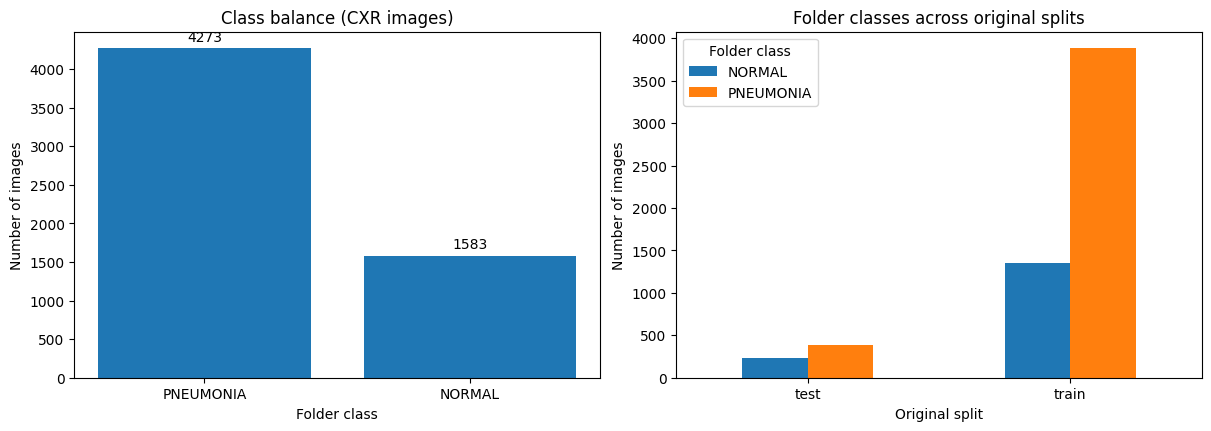

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True)
class_view = class_counts[class_counts["class"].isin(["NORMAL", "PNEUMONIA"])]
axes[0].bar(class_view["class"], class_view["images"])
axes[0].set(title="Class balance (CXR images)", ylabel="Number of images", xlabel="Folder class")
axes[0].bar_label(axes[0].containers[0], padding=3)
by_split.reindex(columns=["NORMAL", "PNEUMONIA"], fill_value=0).plot(kind="bar", ax=axes[1])
axes[1].set(title="Folder classes across original splits", ylabel="Number of images", xlabel="Original split")
axes[1].tick_params(axis="x", rotation=0)
axes[1].legend(title="Folder class", loc="best")
fig.savefig(OUTPUT_DIR / "class_and_split_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

## 4. Full image integrity check and dimensions

This checks that Pillow can **decode the full image data**, not merely parse its header. It records image shape, mode, format, grayscale average, and a small 64-bit difference hash (`dHash`) for later *candidate* screening. Similar dHashes do **not** imply images are duplicates: X-rays share visual structure, so matching candidates must be reviewed manually.

In [10]:
@contextmanager
def open_source_bytes(rel):
    if source_type == "zip":
        with zip_handle.open(rel, mode="r") as stream:
            yield stream
    else:
        with open(selected_source / rel, "rb") as stream:
            yield stream

def difference_hash(img):
    # Tiny grayscale fingerprint, deliberately not a clinical similarity metric.
    pixels = np.asarray(img.convert("L").resize((9, 8), Image.Resampling.BILINEAR), dtype=np.int16)
    bits = (pixels[:, 1:] >= pixels[:, :-1]).reshape(-1)
    number = 0
    for bit in bits:
        number = (number << 1) | int(bit)
    return f"{number:016x}"

def image_quality_record(row):
    output = {"image_decode_ok": False, "width": np.nan, "height": np.nan,
              "aspect_ratio": np.nan, "image_mode": None, "image_format": None,
              "mean_grayscale": np.nan, "dhash64": None, "image_error": None}
    try:
        with open_source_bytes(row["relative_path"]) as stream:
            with Image.open(stream) as img:
                w, h = img.size
                output.update(width=w, height=h, aspect_ratio=w / h if h else np.nan,
                              image_mode=str(img.mode), image_format=str(img.format))
                if FULL_DECODE_CHECK:
                    img.load()
                if COMPUTE_DHASH:
                    output["dhash64"] = difference_hash(img)
                gray_thumb = img.convert("L").resize((32, 32), Image.Resampling.BILINEAR)
                output["mean_grayscale"] = float(np.asarray(gray_thumb, dtype=np.float32).mean())
                output["image_decode_ok"] = bool(FULL_DECODE_CHECK)
    except Exception as exc:
        output["image_error"] = type(exc).__name__ + ": " + str(exc)[:180]
    return output

quality_results = []
for item in tqdm(cxr.to_dict("records"), total=len(cxr), desc="Checking CXR image integrity"):
    quality_results.append(image_quality_record(item))
quality = pd.DataFrame(quality_results)
cxr = pd.concat([cxr.reset_index(drop=True), quality.reset_index(drop=True)], axis=1)
failed = cxr.loc[cxr["image_error"].notna() | (cxr["file_size_bytes"] <= 0)].copy()
print("Full image decode enabled:", FULL_DECODE_CHECK)
print("Confirmed fully decoded:", int(cxr["image_decode_ok"].sum()), "/", len(cxr))
print("Image reading failures:", int(cxr["image_error"].notna().sum()))
print("Image sizes (pixels):")
display(cxr[["width", "height", "aspect_ratio"]].describe().round(2))
print("Image modes:")
display(cxr["image_mode"].value_counts(dropna=False).to_frame("count"))
if not failed.empty:
    display(failed[["relative_path", "image_error", "file_size_bytes"]].head(20))
failed.to_csv(OUTPUT_DIR / "image_integrity_failures.csv", index=False)

Checking CXR image integrity:   0%|          | 0/5856 [00:00<?, ?it/s]

Full image decode enabled: True
Confirmed fully decoded: 5856 / 5856
Image reading failures: 0
Image sizes (pixels):


,width,height,aspect_ratio
count,5856.00,5856.00,5856.00
mean,1328.48,974.16,1.44
std,364.02,386.40,0.26
min,384.00,127.00,0.84
25%,1056.00,688.00,1.26
50%,1281.00,888.00,1.41
75%,1560.00,1195.50,1.58
max,2916.00,2713.00,3.38


Image modes:


,count
image_mode,
L,5573
RGB,283


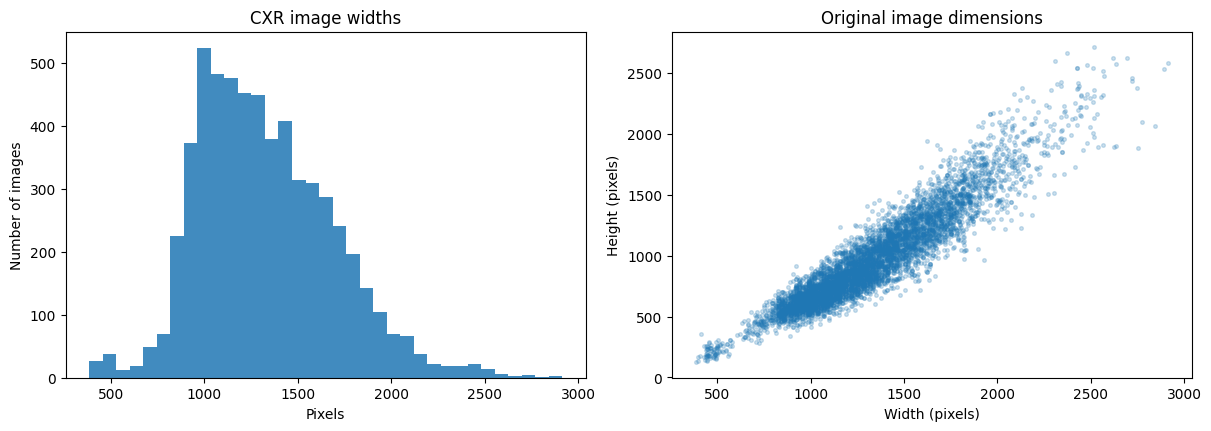

In [11]:
valid_dims = cxr.dropna(subset=["width", "height"])
if not valid_dims.empty:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True)
    axes[0].hist(valid_dims["width"], bins=35, alpha=0.85)
    axes[0].set(title="CXR image widths", xlabel="Pixels", ylabel="Number of images")
    axes[1].scatter(valid_dims["width"], valid_dims["height"], s=7, alpha=0.22)
    axes[1].set(title="Original image dimensions", xlabel="Width (pixels)", ylabel="Height (pixels)")
    fig.savefig(OUTPUT_DIR / "image_dimensions.png", dpi=160, bbox_inches="tight")
    plt.show()

## 5. Identity and grouping audit

**Crucial limitation:** `NORMAL-1003233-0001.jpeg` contains a numeric group token, but it is **not a verified patient ID**. We report token coverage, token overlaps across original splits, and tokens associated with multiple *filename subtypes*. Neither zero overlaps nor 100% token coverage proves patient independence.

If you have authoritative dataset metadata, create a CSV with the two columns `relative_path,verified_patient_id` and set `VERIFIED_PATIENT_CSV` above. Do not use guesses or raw names/medical identifiers here; de-identified IDs are sufficient.

In [12]:
cxr["verified_patient_id"] = pd.Series([pd.NA] * len(cxr), dtype="string")
if VERIFIED_PATIENT_CSV:
    mapped = pd.read_csv(VERIFIED_PATIENT_CSV, dtype="string")
    required = {"relative_path", "verified_patient_id"}
    if not required.issubset(mapped.columns):
        raise ValueError(f"Verified mapping CSV must contain columns {sorted(required)}")
    if mapped["relative_path"].duplicated().any():
        raise ValueError("Verified mapping has duplicate relative_path records; resolve manually.")
    map_lookup = mapped.set_index("relative_path")["verified_patient_id"]
    cxr["verified_patient_id"] = cxr["relative_path"].map(map_lookup).astype("string")

patient_coverage = int(cxr["verified_patient_id"].notna().sum())
print(f"Verified patient identity coverage: {patient_coverage:,} / {len(cxr):,}")
print("Unverified filename group coverage:", int(cxr["numeric_group_candidate_UNVERIFIED"].notna().sum()))

candidate_rows = cxr.dropna(subset=["numeric_group_candidate_UNVERIFIED"])
if candidate_rows.empty:
    group_diagnostics = pd.DataFrame(columns=["numeric_group_candidate_UNVERIFIED", "images", "original_splits", "folder_classes", "filename_subtypes", "n_splits", "n_classes", "n_subtypes"])
else:
    group_diagnostics = (candidate_rows.groupby("numeric_group_candidate_UNVERIFIED", dropna=False)
        .agg(images=("image_id", "count"),
             original_splits=("original_split", lambda s: ",".join(sorted(set(s)))),
             folder_classes=("label", lambda s: ",".join(sorted(set(s)))),
             filename_subtypes=("subtype_filename_token", lambda s: ",".join(sorted(set(s) - {"UNKNOWN"}))),
             n_splits=("original_split", "nunique"), n_classes=("label", "nunique"),
             n_subtypes=("subtype_filename_token", lambda s: len(set(s)-{"UNKNOWN"})))
        .reset_index())

cross_split_candidates = group_diagnostics[group_diagnostics["n_splits"] > 1]
mixed_class_candidates = group_diagnostics[group_diagnostics["n_classes"] > 1]
mixed_subtype_candidates = group_diagnostics[group_diagnostics["n_subtypes"] > 1]
print("Distinct unverified numeric tokens:", len(group_diagnostics))
print("Tokens spanning original splits:", len(cross_split_candidates))
print("Tokens spanning binary classes:", len(mixed_class_candidates))
print("Tokens with mixed BACTERIAL/VIRAL filename labels:", len(mixed_subtype_candidates))
if not mixed_subtype_candidates.empty:
    display(mixed_subtype_candidates.sort_values("images", ascending=False).head(12))
group_diagnostics.to_csv(OUTPUT_DIR / "unverified_numeric_token_diagnostics.csv", index=False)
cross_split_candidates.to_csv(OUTPUT_DIR / "unverified_token_cross_split.csv", index=False)
mixed_subtype_candidates.to_csv(OUTPUT_DIR / "unverified_token_mixed_subtypes.csv", index=False)

if patient_coverage:
    verified_rows = cxr.dropna(subset=["verified_patient_id"])
    verified_overlap = (verified_rows.groupby("verified_patient_id")["original_split"].nunique() > 1)
    verified_cross_split = int(verified_overlap.sum())
else:
    verified_cross_split = None
print("Verified patient IDs spanning original splits:", verified_cross_split if verified_cross_split is not None else "NOT ASSESSABLE")

Verified patient identity coverage: 0 / 5,856
Unverified filename group coverage: 5856
Distinct unverified numeric tokens: 3081
Tokens spanning original splits: 0
Tokens spanning binary classes: 0
Tokens with mixed BACTERIAL/VIRAL filename labels: 809


,numeric_group_candidate_UNVERIFIED,images,original_splits,folder_classes,filename_subtypes,n_splits,n_classes,n_subtypes
1404,5150733,18,train,PNEUMONIA,"BACTERIAL,VIRAL",1,1,2
1593,5628383,14,train,PNEUMONIA,"BACTERIAL,VIRAL",1,1,2
2332,7794093,13,train,PNEUMONIA,"BACTERIAL,VIRAL",1,1,2
2663,8738712,12,train,PNEUMONIA,"BACTERIAL,VIRAL",1,1,2
1740,6076468,12,train,PNEUMONIA,"BACTERIAL,VIRAL",1,1,2
2636,8660561,12,train,PNEUMONIA,"BACTERIAL,VIRAL",1,1,2
1186,4462203,12,train,PNEUMONIA,"BACTERIAL,VIRAL",1,1,2
1231,4615614,11,train,PNEUMONIA,"BACTERIAL,VIRAL",1,1,2
1818,6295192,11,train,PNEUMONIA,"BACTERIAL,VIRAL",1,1,2
2595,8550709,11,train,PNEUMONIA,"BACTERIAL,VIRAL",1,1,2


Verified patient IDs spanning original splits: NOT ASSESSABLE


## 6. Exact duplicates (SHA-256)

Hash each selected image's raw bytes. Same SHA-256 means byte-identical files. This is a strong integrity check; it does **not** detect image copies with different compression, crops, or rescaling. Do not automatically delete an example from the test set.

In [13]:
def hash_image_bytes(relative_path):
    digest = hashlib.sha256()
    with open_source_bytes(relative_path) as fh:
        for chunk in iter(lambda: fh.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

sha_values, hash_errors = [], []
if COMPUTE_SHA256:
    for rel in tqdm(cxr["relative_path"], total=len(cxr), desc="SHA-256 exact duplicates"):
        try:
            sha_values.append(hash_image_bytes(rel))
            hash_errors.append(None)
        except Exception as exc:
            sha_values.append(None)
            hash_errors.append(f"{type(exc).__name__}: {str(exc)[:150]}")
else:
    sha_values = [None] * len(cxr)
    hash_errors = ["not run"] * len(cxr)
cxr["sha256"] = sha_values
cxr["sha_error"] = hash_errors

with_hash = cxr[cxr["sha256"].notna()]
exact_duplicates = with_hash[with_hash.duplicated("sha256", keep=False)].copy()
if not exact_duplicates.empty:
    exact_duplicates["group_image_count"] = exact_duplicates.groupby("sha256")["sha256"].transform("size")
    exact_duplicates = exact_duplicates.sort_values(["sha256", "original_split", "relative_path"])
    duplicate_hash_groups = int(exact_duplicates["sha256"].nunique())
    duplicate_redundant_copies = len(exact_duplicates) - duplicate_hash_groups
    exact_cross_split_groups = int((exact_duplicates.groupby("sha256")["original_split"].nunique() > 1).sum())
    exact_conflicting_class_groups = int((exact_duplicates.groupby("sha256")["label"].nunique() > 1).sum())
else:
    duplicate_hash_groups = duplicate_redundant_copies = exact_cross_split_groups = exact_conflicting_class_groups = 0

print("Exact-duplicate hash groups:", duplicate_hash_groups)
print("Images belonging to duplicate groups:", len(exact_duplicates))
print("Extra copies beyond one per group:", duplicate_redundant_copies)
print("Duplicate hash groups crossing original splits:", exact_cross_split_groups)
print("Duplicate hash groups with conflicting folder class labels:", exact_conflicting_class_groups)
print("Hash failures:", int(cxr["sha_error"].notna().sum()))
if not exact_duplicates.empty:
    display(exact_duplicates[["relative_path", "original_split", "label", "group_image_count"]].head(14))
exact_duplicates.to_csv(OUTPUT_DIR / "exact_duplicate_images.csv", index=False)

SHA-256 exact duplicates:   0%|          | 0/5856 [00:00<?, ?it/s]

Exact-duplicate hash groups: 27
Images belonging to duplicate groups: 56
Extra copies beyond one per group: 29
Duplicate hash groups crossing original splits: 0
Duplicate hash groups with conflicting folder class labels: 0
Hash failures: 0


,relative_path,original_split,label,group_image_count
4552,srabondcosta/pneumonia/ZhangLabData/CellData/chest_xray/train/PNEUMONIA/VIRUS-1213217-...,train,PNEUMONIA,2
4553,srabondcosta/pneumonia/ZhangLabData/CellData/chest_xray/train/PNEUMONIA/VIRUS-1213217-...,train,PNEUMONIA,2
5052,srabondcosta/pneumonia/ZhangLabData/CellData/chest_xray/train/PNEUMONIA/VIRUS-463487-0...,train,PNEUMONIA,2
5053,srabondcosta/pneumonia/ZhangLabData/CellData/chest_xray/train/PNEUMONIA/VIRUS-463487-0...,train,PNEUMONIA,2
5730,srabondcosta/pneumonia/ZhangLabData/CellData/chest_xray/train/PNEUMONIA/VIRUS-9130179-...,train,PNEUMONIA,2
5731,srabondcosta/pneumonia/ZhangLabData/CellData/chest_xray/train/PNEUMONIA/VIRUS-9130179-...,train,PNEUMONIA,2
1027,srabondcosta/pneumonia/ZhangLabData/CellData/chest_xray/train/NORMAL/NORMAL-3780378-00...,train,NORMAL,2
1028,srabondcosta/pneumonia/ZhangLabData/CellData/chest_xray/train/NORMAL/NORMAL-3780378-00...,train,NORMAL,2
3526,srabondcosta/pneumonia/ZhangLabData/CellData/chest_xray/train/PNEUMONIA/BACTERIA-64209...,train,PNEUMONIA,2
3527,srabondcosta/pneumonia/ZhangLabData/CellData/chest_xray/train/PNEUMONIA/BACTERIA-64209...,train,PNEUMONIA,2


## 7. Perceptual near-duplicate screening (manual review required)

64-bit dHash finds **visually similar** image candidates across different original splits. Similar chest radiographs often have similar dHashes, so a match is **not proof of data leakage**. We exclude already byte-identical pairs from this candidate list. No images are deleted, relabeled, or reassigned.

If the candidate comparison exceeds the configured safety limit, we explicitly mark this check as *not completed* instead of silently claiming a pass.

In [14]:
near_duplicate_matches = []
near_duplicate_count = 0
near_duplicate_comparisons = 0
near_duplicate_check_status = "NOT_RUN"

if COMPUTE_DHASH:
    candidates = cxr[(cxr["dhash64"].notna()) &
                     (cxr["original_split"].isin(ALLOWED_SPLITS))].copy()
    by_fold = {split: frame.to_dict("records") for split, frame in candidates.groupby("original_split")}
    distinct_splits = sorted(by_fold.keys())
    total_pairs = sum(len(by_fold[a]) * len(by_fold[b]) for a, b in combinations(distinct_splits, 2))
    print("Cross-split dHash comparisons planned:", f"{total_pairs:,}")
    if total_pairs > MAX_CROSS_SPLIT_DHASH_COMPARISONS:
        near_duplicate_check_status = "SKIPPED_PAIR_SAFETY_LIMIT"
        print("REVIEW: pair count exceeds safety limit. No negative claim can be made.")
    else:
        near_duplicate_check_status = "COMPLETED"
        for split_a, split_b in combinations(distinct_splits, 2):
            for row_a in tqdm(by_fold[split_a], desc=f"dHash {split_a} vs {split_b}"):
                hash_a = int(row_a["dhash64"], 16)
                for row_b in by_fold[split_b]:
                    near_duplicate_comparisons += 1
                    if row_a["sha256"] is not None and row_a["sha256"] == row_b["sha256"]:
                        continue  # Already covered by exact duplicates.
                    distance = (hash_a ^ int(row_b["dhash64"], 16)).bit_count()
                    if distance <= NEAR_DUPLICATE_MAX_HAMMING:
                        near_duplicate_count += 1
                        if len(near_duplicate_matches) < MAX_NEAR_DUPLICATE_OUTPUT_ROWS:
                            near_duplicate_matches.append({
                                "split_a": split_a, "split_b": split_b,
                                "path_a": row_a["relative_path"], "path_b": row_b["relative_path"],
                                "label_a": row_a["label"], "label_b": row_b["label"],
                                "hamming_distance": distance,
                                "manual_review": "UNREVIEWED_CANDIDATE_NOT_PROVEN_DUPLICATE"
                            })
else:
    print("dHash computation disabled. Near-duplicate screening not performed.")

near_duplicates_df = pd.DataFrame(near_duplicate_matches, columns=[
    "split_a", "split_b", "path_a", "path_b", "label_a", "label_b",
    "hamming_distance", "manual_review"
])
near_duplicates_df.to_csv(OUTPUT_DIR / "cross_split_near_duplicate_CANDIDATES.csv", index=False)
print("dHash screening status:", near_duplicate_check_status)
print("Pairs flagged for manual review:", near_duplicate_count)
print("Rows saved (bounded):", len(near_duplicates_df))
if not near_duplicates_df.empty:
    display(near_duplicates_df.head(12))

Cross-split dHash comparisons planned: 3,264,768


dHash test vs train:   0%|          | 0/624 [00:00<?, ?it/s]

dHash screening status: COMPLETED
Pairs flagged for manual review: 214758
Rows saved (bounded): 1000


,split_a,split_b,path_a,path_b,label_a,label_b,hamming_distance,manual_review
0,test,train,srabondcosta/pneumonia/ZhangLabData/CellData/chest_xray/test/NORMAL/NORMAL-1049278-000...,srabondcosta/pneumonia/ZhangLabData/CellData/chest_xray/train/NORMAL/NORMAL-1044645-00...,NORMAL,NORMAL,4,UNREVIEWED_CANDIDATE_NOT_PROVEN_DUPLICATE
1,test,train,srabondcosta/pneumonia/ZhangLabData/CellData/chest_xray/test/NORMAL/NORMAL-1049278-000...,srabondcosta/pneumonia/ZhangLabData/CellData/chest_xray/train/NORMAL/NORMAL-1798503-00...,NORMAL,NORMAL,4,UNREVIEWED_CANDIDATE_NOT_PROVEN_DUPLICATE
2,test,train,srabondcosta/pneumonia/ZhangLabData/CellData/chest_xray/test/NORMAL/NORMAL-1049278-000...,srabondcosta/pneumonia/ZhangLabData/CellData/chest_xray/train/NORMAL/NORMAL-2415177-00...,NORMAL,NORMAL,4,UNREVIEWED_CANDIDATE_NOT_PROVEN_DUPLICATE
3,test,train,srabondcosta/pneumonia/ZhangLabData/CellData/chest_xray/test/NORMAL/NORMAL-1049278-000...,srabondcosta/pneumonia/ZhangLabData/CellData/chest_xray/train/NORMAL/NORMAL-3108988-00...,NORMAL,NORMAL,4,UNREVIEWED_CANDIDATE_NOT_PROVEN_DUPLICATE
4,test,train,srabondcosta/pneumonia/ZhangLabData/CellData/chest_xray/test/NORMAL/NORMAL-1049278-000...,srabondcosta/pneumonia/ZhangLabData/CellData/chest_xray/train/NORMAL/NORMAL-3269314-00...,NORMAL,NORMAL,4,UNREVIEWED_CANDIDATE_NOT_PROVEN_DUPLICATE
5,test,train,srabondcosta/pneumonia/ZhangLabData/CellData/chest_xray/test/NORMAL/NORMAL-1049278-000...,srabondcosta/pneumonia/ZhangLabData/CellData/chest_xray/train/NORMAL/NORMAL-4199443-00...,NORMAL,NORMAL,4,UNREVIEWED_CANDIDATE_NOT_PROVEN_DUPLICATE
6,test,train,srabondcosta/pneumonia/ZhangLabData/CellData/chest_xray/test/NORMAL/NORMAL-1049278-000...,srabondcosta/pneumonia/ZhangLabData/CellData/chest_xray/train/NORMAL/NORMAL-4758820-00...,NORMAL,NORMAL,4,UNREVIEWED_CANDIDATE_NOT_PROVEN_DUPLICATE
7,test,train,srabondcosta/pneumonia/ZhangLabData/CellData/chest_xray/test/NORMAL/NORMAL-1049278-000...,srabondcosta/pneumonia/ZhangLabData/CellData/chest_xray/train/NORMAL/NORMAL-5693915-00...,NORMAL,NORMAL,4,UNREVIEWED_CANDIDATE_NOT_PROVEN_DUPLICATE
8,test,train,srabondcosta/pneumonia/ZhangLabData/CellData/chest_xray/test/NORMAL/NORMAL-1049278-000...,srabondcosta/pneumonia/ZhangLabData/CellData/chest_xray/train/NORMAL/NORMAL-6367802-00...,NORMAL,NORMAL,4,UNREVIEWED_CANDIDATE_NOT_PROVEN_DUPLICATE
9,test,train,srabondcosta/pneumonia/ZhangLabData/CellData/chest_xray/test/NORMAL/NORMAL-1049278-000...,srabondcosta/pneumonia/ZhangLabData/CellData/chest_xray/train/NORMAL/NORMAL-6978858-00...,NORMAL,NORMAL,4,UNREVIEWED_CANDIDATE_NOT_PROVEN_DUPLICATE


## 8. Optional verified patient-grouped validation split

**Default: disabled.** This notebook never treats `numeric_group_candidate_UNVERIFIED` as a patient ID. To enable validation splitting:

1. Obtain trustworthy source metadata mapping **every** CXR to a verified, de-identified patient ID.
2. Supply `VERIFIED_PATIENT_CSV` and set `CREATE_VAL_IF_PATIENT_VERIFIED=True`.
3. Confirm no verified patient IDs or exact duplicates span original train/test.
4. Use original `test` unchanged; partition *original train* into train/val with complete verified groups and exact-duplicate components kept together.

An output here is a **proposed data manifest**, not permission to describe the model as externally or clinically validated.

In [15]:
proposed_manifest = None
split_creation_status = "NOT_REQUESTED"
if CREATE_VAL_IF_PATIENT_VERIFIED:
    prerequisites = []
    if VERIFIED_PATIENT_CSV is None or patient_coverage != len(cxr):
        prerequisites.append("verified patient IDs are missing or incomplete")
    if set(cxr["original_split"]) != {"train", "test"}:
        prerequisites.append("expected original train/test only (no existing val/UNKNOWN)")
    if verified_cross_split not in (0,):
        prerequisites.append("verified patient ID overlap across original splits cannot be ruled out")
    if exact_cross_split_groups:
        prerequisites.append("exact duplicates cross original split boundaries")
    if not COMPUTE_SHA256 or cxr["sha_error"].notna().any():
        prerequisites.append("complete SHA-256 check is required")
    if prerequisites:
        split_creation_status = "BLOCKED: " + "; ".join(prerequisites)
        print(split_creation_status)
    else:
        from sklearn.model_selection import GroupShuffleSplit
        training = cxr[cxr["original_split"] == "train"].copy().reset_index(drop=True)

        # Union confirmed patient and exact-duplicate relationships into group components.
        parent = list(range(len(training)))
        def find_group(i):
            while parent[i] != i:
                parent[i] = parent[parent[i]]
                i = parent[i]
            return i
        def union_groups(i, j):
            a, b = find_group(i), find_group(j)
            if a != b:
                parent[b] = a
        for col in ("verified_patient_id", "sha256"):
            first_for_value = {}
            for i, value in enumerate(training[col].tolist()):
                if pd.isna(value):
                    continue
                if value in first_for_value:
                    union_groups(first_for_value[value], i)
                else:
                    first_for_value[value] = i

        groups = np.array([find_group(i) for i in range(len(training))])
        labels = training["label"].to_numpy()
        preferred_pos = float((labels == "PNEUMONIA").mean())
        splitter = GroupShuffleSplit(n_splits=60, test_size=VAL_FRACTION_OF_ORIGINAL_TRAIN, random_state=SEED)
        best = None
        for train_ix, val_ix in splitter.split(training, labels, groups):
            lab_train, lab_val = labels[train_ix], labels[val_ix]
            if len(set(lab_train)) != 2 or len(set(lab_val)) != 2:
                continue
            score = (abs(len(val_ix) / len(training) - VAL_FRACTION_OF_ORIGINAL_TRAIN)
                     + abs((lab_val == "PNEUMONIA").mean() - preferred_pos))
            if best is None or score < best[0]:
                best = (score, train_ix, val_ix)
        if best is None:
            raise RuntimeError("No balanced-enough grouped validation partition was found; manual review required.")

        proposed_manifest = cxr.copy()
        proposed_manifest["proposed_split"] = proposed_manifest["original_split"]
        val_paths = set(training.iloc[best[2]]["relative_path"])
        proposed_manifest.loc[proposed_manifest["relative_path"].isin(val_paths), "proposed_split"] = "val"
        assert (proposed_manifest.loc[proposed_manifest["original_split"] == "test", "proposed_split"] == "test").all()
        assert (proposed_manifest.groupby("verified_patient_id")["proposed_split"].nunique() <= 1).all()
        assert (proposed_manifest.groupby("sha256")["proposed_split"].nunique() <= 1).all()
        proposed_manifest.to_csv(OUTPUT_DIR / "PROPOSED_verified_grouped_split_manifest.csv", index=False)
        split_creation_status = "PROPOSED_VALIDATION_CREATED_NEEDS_REVIEW"
        print(split_creation_status)
        display(pd.crosstab(proposed_manifest["proposed_split"], proposed_manifest["label"]))
else:
    print("No split generated: verified patient grouping has not been authorized.")

No split generated: verified patient grouping has not been authorized.


## 9. Audit report, evidence bundle, and phase gates

**Pass/fail logic:** data are **ready for EDA** when candidate images are accessible, label/split parsing is complete, and image integrity checks pass. Model training additionally requires an approved *non-leaky* validation plan. This does not assert real-world clinical validity. No automatic cleaning or test-set tuning is performed.

In [16]:
from textwrap import dedent

n_hash_errors = int(cxr["sha_error"].notna().sum()) if COMPUTE_SHA256 else len(cxr)
n_decode_errors = int(cxr["image_error"].notna().sum())
n_unknown_class = int((cxr["label"] == "UNKNOWN").sum())
n_unknown_split = int((cxr["original_split"] == "UNKNOWN").sum())
n_label_disagree = int(cxr["folder_filename_label_conflict"].sum())
verified_split_ok = (patient_coverage == len(cxr)
                     and verified_cross_split == 0
                     and ("val" in cxr["original_split"].values or proposed_manifest is not None))
complete_integrity_check = bool(FULL_DECODE_CHECK and COMPUTE_SHA256 and COMPUTE_DHASH and
                                near_duplicate_check_status == "COMPLETED")
ready_for_eda = bool(len(cxr)>0 and FULL_DECODE_CHECK and n_decode_errors==0
                     and n_unknown_class==0 and n_unknown_split==0
                     and n_label_disagree==0 and zero_byte_files==0 and fallback_rows==0)
ready_for_training_split_review = bool(ready_for_eda and COMPUTE_SHA256 and n_hash_errors == 0
                                       and exact_cross_split_groups == 0 and verified_split_ok)

warnings_list = []
if not FULL_DECODE_CHECK: warnings_list.append("Only image headers / thumbnails checked, not full decode")
if n_decode_errors: warnings_list.append(f"Unreadable image files: {n_decode_errors}")
if n_hash_errors: warnings_list.append(f"Unhashed image files: {n_hash_errors}")
if n_unknown_class: warnings_list.append(f"Unknown binary folder labels: {n_unknown_class}")
if n_unknown_split: warnings_list.append(f"Missing original split labels: {n_unknown_split}")
if n_label_disagree: warnings_list.append(f"Folder/filename class conflicts: {n_label_disagree}")
if zero_byte_files: warnings_list.append(f"Empty files / invalid file sizes: {zero_byte_files}")
if fallback_rows: warnings_list.append(f"CXR modality depends on unconfirmed fallback: {fallback_rows}")
if "val" not in cxr["original_split"].values and proposed_manifest is None:
    warnings_list.append("No approved validation split; original test must remain untouched")
if patient_coverage != len(cxr):
    warnings_list.append("Patient-level independence is NOT verified: trusted patient ID mapping incomplete")
if verified_cross_split not in (None, 0):
    warnings_list.append(f"Verified patients crossing original splits: {verified_cross_split}")
if exact_cross_split_groups:
    warnings_list.append(f"Exact duplicate groups crossing original splits: {exact_cross_split_groups}")
if len(exact_duplicates):
    warnings_list.append(f"Exact duplicates within source: {len(exact_duplicates)} image rows in {duplicate_hash_groups} groups")
if len(mixed_subtype_candidates):
    warnings_list.append(f"Mixed bacterial/viral filename tokens in {len(mixed_subtype_candidates)} UNVERIFIED numeric groups")
if near_duplicate_check_status != "COMPLETED":
    warnings_list.append(f"Cross-split dHash screen not completed: {near_duplicate_check_status}")
elif near_duplicate_count:
    warnings_list.append(f"Cross-split dHash candidate pairs requiring manual review: {near_duplicate_count}")
if not CREATE_VAL_IF_PATIENT_VERIFIED:
    warnings_list.append("No verified patient-grouped validation split was requested")

summary = {
    "project": "PneumoLens", "phase": "Phase 2", "notebook": "01_Dataset_Audit_V2",
    "audit_utc": datetime.now(timezone.utc).isoformat(),
    "selected_source": str(selected_source), "source_type": source_type,
    "inventory_all_images": int(len(inventory)),
    "cxr_image_candidates": int(len(cxr)),
    "excluded_other_or_uncertain_images": int(len(inventory) - len(cxr)),
    "class_counts": {str(k): int(v) for k,v in cxr["label"].value_counts().items()},
    "original_split_counts": {str(k): int(v) for k,v in cxr["original_split"].value_counts().items()},
    "subtype_filename_token_counts": {str(k): int(v) for k,v in cxr.loc[cxr["label"]=="PNEUMONIA","subtype_filename_token"].value_counts().items()},
    "label_folder_filename_disagreements": n_label_disagree,
    "fallback_modality_rows": fallback_rows,
    "full_decode_enabled": bool(FULL_DECODE_CHECK),
    "confirmed_full_decodes": int(cxr["image_decode_ok"].sum()),
    "image_decode_errors": n_decode_errors,
    "sha256_enabled": bool(COMPUTE_SHA256), "sha256_errors": n_hash_errors,
    "exact_duplicate_groups": duplicate_hash_groups,
    "exact_duplicate_image_rows": int(len(exact_duplicates)),
    "redundant_copies_within_duplicate_groups": duplicate_redundant_copies,
    "exact_duplicate_groups_cross_original_splits": exact_cross_split_groups,
    "unverified_numeric_token_groups": int(len(group_diagnostics)),
    "unverified_numeric_tokens_cross_splits": int(len(cross_split_candidates)),
    "unverified_numeric_tokens_mixed_subtypes": int(len(mixed_subtype_candidates)),
    "verified_patient_coverage": patient_coverage,
    "verified_patients_cross_original_splits": verified_cross_split,
    "near_duplicate_screen_status": near_duplicate_check_status,
    "near_duplicate_hamming_threshold": NEAR_DUPLICATE_MAX_HAMMING,
    "near_duplicate_candidate_pairs": near_duplicate_count,
    "near_duplicate_comparisons_completed": near_duplicate_comparisons,
    "validation_manifest_status": split_creation_status,
    "ready_for_eda": ready_for_eda,
    "ready_for_training_split_review": ready_for_training_split_review,
    "full_audit_checks_completed": complete_integrity_check,
    "warnings": warnings_list,
    "limitation": "Image-file analysis only; no proof of patient independence or clinical validity without trusted metadata/external validation.",
}

if SAVE_ALL_IMAGE_INVENTORY:
    inventory.to_csv(OUTPUT_DIR / "all_image_inventory.csv", index=False)
cxr.to_csv(OUTPUT_DIR / "chest_xray_manifest_V2.csv", index=False)
with open(OUTPUT_DIR / "audit_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)

report = [
    "# PneumoLens | Phase 2 Data Audit V2", "",
    f"UTC date: {summary['audit_utc']}",
    f"Dataset source: `{selected_source}` ({source_type})", "",
    "## Dataset counts (image-level)",
    f"- All image files inventoried: {len(inventory):,}",
    f"- Chest X-ray candidates: {len(cxr):,}",
    f"- Excluded or uncertain non-CXR images: {len(inventory)-len(cxr):,}",
    f"- Original split counts: {summary['original_split_counts']}",
    f"- Class counts: {summary['class_counts']}",
    f"- Pneumonia filename subtype counts: {summary['subtype_filename_token_counts']}", "",
    "## Integrity and grouping", 
    f"- Fully decoded images: {summary['confirmed_full_decodes']:,} / {len(cxr):,}",
    f"- SHA256 exact duplicate groups: {duplicate_hash_groups} ({len(exact_duplicates)} image rows)",
    f"- Cross-split exact duplicate groups: {exact_cross_split_groups}",
    f"- Unverified numeric tokens: {len(group_diagnostics):,} (mixed subtype tokens: {len(mixed_subtype_candidates):,})",
    f"- Verified patient IDs available: {patient_coverage:,} / {len(cxr):,}",
    f"- Cross-split near-duplicate screening: {near_duplicate_check_status} ({near_duplicate_count} candidates)", "",
    "## Phase gates", f"- EDA gate: {'PASS' if ready_for_eda else 'REVIEW'}",
    f"- Training/split-review gate: {'PASS - requires human approval' if ready_for_training_split_review else 'BLOCKED'}", "",
    "## Warnings / required actions"
]
report.extend(f"- {line}" for line in warnings_list)
report.extend([
    "", "## Methodological limits", 
    "- Filename numeric tokens are NOT automatically verified patient IDs.",
    "- Cross-split dHash matches are review candidates, not confirmed duplicates.",
    "- Subtype filename tokens are not pathogen confirmation.",
    "- Original test is never used for selecting architecture, hyperparameters, or decision threshold.",
    "- Single-source pediatric chest radiographs do not establish clinical safety or cross-hospital generalization.",
])
(OUTPUT_DIR / "audit_report.md").write_text("\n".join(report) + "\n", encoding="utf-8")

print("\n" + "="*74)
print("PNEUMOLENS PHASE 2 | FINAL AUDIT")
print("="*74)
for item in ["inventory_all_images", "cxr_image_candidates", "confirmed_full_decodes",
             "exact_duplicate_groups", "exact_duplicate_groups_cross_original_splits",
             "unverified_numeric_tokens_mixed_subtypes", "verified_patient_coverage",
             "near_duplicate_screen_status", "near_duplicate_candidate_pairs"]:
    print(f"{item:49s} {summary[item]}")
print("EDA ready:", ready_for_eda)
print("Training split review ready:", ready_for_training_split_review)
print("Output folder:", OUTPUT_DIR)
print("Actionable warnings:")
for issue in warnings_list[:16]:
    print("  -", issue)

if zip_handle is not None:
    zip_handle.close()


PNEUMOLENS PHASE 2 | FINAL AUDIT
inventory_all_images                              115165
cxr_image_candidates                              5856
confirmed_full_decodes                            5856
exact_duplicate_groups                            27
exact_duplicate_groups_cross_original_splits      0
unverified_numeric_tokens_mixed_subtypes          809
verified_patient_coverage                         0
near_duplicate_screen_status                      COMPLETED
near_duplicate_candidate_pairs                    214758
EDA ready: True
Training split review ready: False
Output folder: /kaggle/working/pneumolens_phase2_audit_v2
Actionable warnings:
  - No approved validation split; original test must remain untouched
  - Patient-level independence is NOT verified: trusted patient ID mapping incomplete
  - Exact duplicates within source: 56 image rows in 27 groups
  - Mixed bacterial/viral filename tokens in 809 UNVERIFIED numeric groups
  - Cross-split dHash candidate pairs requiring

In [17]:

# ZIP all PneumoLens Phase 2 audit outputs

from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from IPython.display import FileLink, display

output_dir = Path(OUTPUT_DIR)

zip_path = output_dir.parent / "PneumoLens_Phase2_Audit_V2_Outputs.zip"

files = sorted(
    p for p in output_dir.rglob("*")
    if p.is_file() and p != zip_path
)

if not files:
    raise RuntimeError("No audit outputs found. Run the audit first.")

with ZipFile(zip_path, "w", ZIP_DEFLATED) as zip_file:
    for file in files:
        zip_file.write(
            file,
            arcname=file.relative_to(output_dir)
        )

print(f"ZIP created successfully: {zip_path}")
print(f"Total files included: {len(files)}")

display(FileLink(str(zip_path)))


ZIP created successfully: /kaggle/working/PneumoLens_Phase2_Audit_V2_Outputs.zip
Total files included: 16


/kaggle/working/PneumoLens_Phase2_Audit_V2_Outputs.zip